# Task 1: Superstore Retail Sales Exploratory Data Analysis (EDA)
**Framework**: RISK (Requirements & Research, Investigation & Insight Discovery, Solution Engineering, Knowledge Delivery & KPI Validation)  
**Objective**: Comprehensive forensic data audit, sales and profitability breakdown, category dynamics, temporal trends, discount elasticity, loss-leader isolation, and commercial strategy formulation.

In [1]:
import os
import sys
from pathlib import Path

# Set project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

from src.data_loader import load_raw_superstore
from src.data_cleaning import clean_superstore
from src.metrics import (
    calculate_superstore_kpis,
    aggregate_superstore_by_dimension,
    aggregate_superstore_monthly,
    analyze_discount_elasticity
)

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Forensic Data Ingestion & Quality Audit
Before performing analytical aggregations, we inspect the raw data file structure.
During forensic profiling, we discover that the raw CSV file contains **10,800 rows**, but rows 9,994 onwards represent concatenated lookup sheets (`People` and `Returns`).

In [2]:
raw_df = load_raw_superstore()
print(f"Raw Superstore Shape: {raw_df.shape}")
print(f"Total Rows: {len(raw_df)}, Total Columns: {len(raw_df.columns)}")

# Inspect the anomaly at row 9994
print("\n--- Inspected Discontinuity at Row 9994 ---")
display_slice = raw_df.iloc[9992:10002][['Row ID', 'Order ID', 'Order Date', 'Sales', 'Profit']]
print(display_slice)

Raw Superstore Shape: (10800, 21)
Total Rows: 10800, Total Columns: 21

--- Inspected Discontinuity at Row 9994 ---
                  Row ID        Order ID Order Date   Sales  Profit
9992                9993  CA-2018-121258  2/26/2018   29.60  13.320
9993                9994  CA-2018-119914   5/4/2018  243.16  72.948
9994              Person          Region        NaN     NaN     NaN
9995       Anna Andreadi            West        NaN     NaN     NaN
9996         Chuck Magee            East        NaN     NaN     NaN
9997      Kelly Williams         Central        NaN     NaN     NaN
9998   Cassandra Brandow           South        NaN     NaN     NaN
9999            Returned        Order ID        NaN     NaN     NaN
10000                Yes  CA-2015-100762        NaN     NaN     NaN
10001                Yes  CA-2015-100762        NaN     NaN     NaN


## 2. Deterministic Cleaning & Feature Engineering
We separate the transactions table (rows 0–9993) from the appended tables:
1. Extract 9,994 retail sales line items.
2. Impute Burlington, Vermont missing postal code with `05401`.
3. Standardize date parsing to datetime64.
4. Extract separate clean tables for Regional Managers and Order Returns.
5. Derive temporal dimensions: `Order Year`, `Order Month`, `Order YearMonth`, `Shipping Days`, and `Discount Band`.

In [3]:
orders_df, people_df, returns_df = clean_superstore()
print(f"Cleaned Orders shape: {orders_df.shape}")
print(f"Regional Managers shape: {people_df.shape}")
print(f"Unique Returns shape: {returns_df.shape}")

# Verify zero nulls across critical fields
critical_nulls = orders_df[['Order ID', 'Order Date', 'Postal Code', 'Sales', 'Profit']].isnull().sum()
print("\nCritical Fields Null Count:\n", critical_nulls)

Cleaned Orders shape: (9994, 30)
Regional Managers shape: (4, 2)
Unique Returns shape: (296, 2)

Critical Fields Null Count:
 Order ID       0
Order Date     0
Postal Code    0
Sales          0
Profit         0
dtype: int64


## 3. High-Level Executive Sales & Profit KPIs
We compute foundational metrics across the 9,994 retail orders.

In [4]:
kpis = calculate_superstore_kpis(orders_df)
kpi_df = pd.DataFrame([
    {"Metric": "Total Sales Revenue", "Value": f"${kpis['total_sales']:,.2f}"},
    {"Metric": "Total Net Profit", "Value": f"${kpis['total_profit']:,.2f}"},
    {"Metric": "Overall Profit Margin", "Value": f"{kpis['profit_margin_pct']:.2f}%"},
    {"Metric": "Total Units Sold", "Value": f"{kpis['total_quantity']:,}"},
    {"Metric": "Total Unique Orders", "Value": f"{kpis['total_orders']:,}"},
    {"Metric": "Average Order Value (AOV)", "Value": f"${kpis['average_order_value']:,.2f}"}
])
print(kpi_df.to_string(index=False))

                   Metric         Value
      Total Sales Revenue $2,297,200.86
         Total Net Profit   $286,397.02
    Overall Profit Margin        12.47%
         Total Units Sold        37,873
      Total Unique Orders         5,009
Average Order Value (AOV)       $458.61


## 4. Category & Sub-Category Performance Analysis
Evaluating revenue and profit contributions across product hierarchies to identify profit drivers and loss leaders.

In [5]:
cat_agg = aggregate_superstore_by_dimension(orders_df, 'Category')
print("--- Category Performance ---")
print(cat_agg.to_string(index=False))

subcat_agg = aggregate_superstore_by_dimension(orders_df, 'Sub-Category')
print("\n--- Top 5 and Bottom 5 Sub-Categories by Profit ---")
print("Top 5 Profitable:")
print(subcat_agg.head(5)[['Sub-Category', 'Sales', 'Profit', 'Profit_Margin_Pct']].to_string(index=False))
print("\nBottom 5 (Loss Leaders & Weak Margins):")
print(subcat_agg.tail(5)[['Sub-Category', 'Sales', 'Profit', 'Profit_Margin_Pct']].to_string(index=False))

--- Category Performance ---
       Category     Sales    Profit  Quantity  Orders  Profit_Margin_Pct  Sales_Share_Pct
     Technology 836154.03 145454.95      6939    1544              17.40             36.4
      Furniture 741999.80  18451.27      8028    1764               2.49             32.3
Office Supplies 719047.03 122490.80     22906    3742              17.04             31.3

--- Top 5 and Bottom 5 Sub-Categories by Profit ---
Top 5 Profitable:
Sub-Category     Sales    Profit  Profit_Margin_Pct
      Phones 330007.05  44515.73              13.49
      Chairs 328449.10  26590.17               8.10
     Storage 223843.61  21278.83               9.51
      Tables 206965.53 -17725.48              -8.56
     Binders 203412.73  30221.76              14.86

Bottom 5 (Loss Leaders & Weak Margins):
Sub-Category    Sales   Profit  Profit_Margin_Pct
    Supplies 46673.54 -1189.10              -2.55
         Art 27118.79  6527.79              24.07
   Envelopes 16476.40  6964.18       

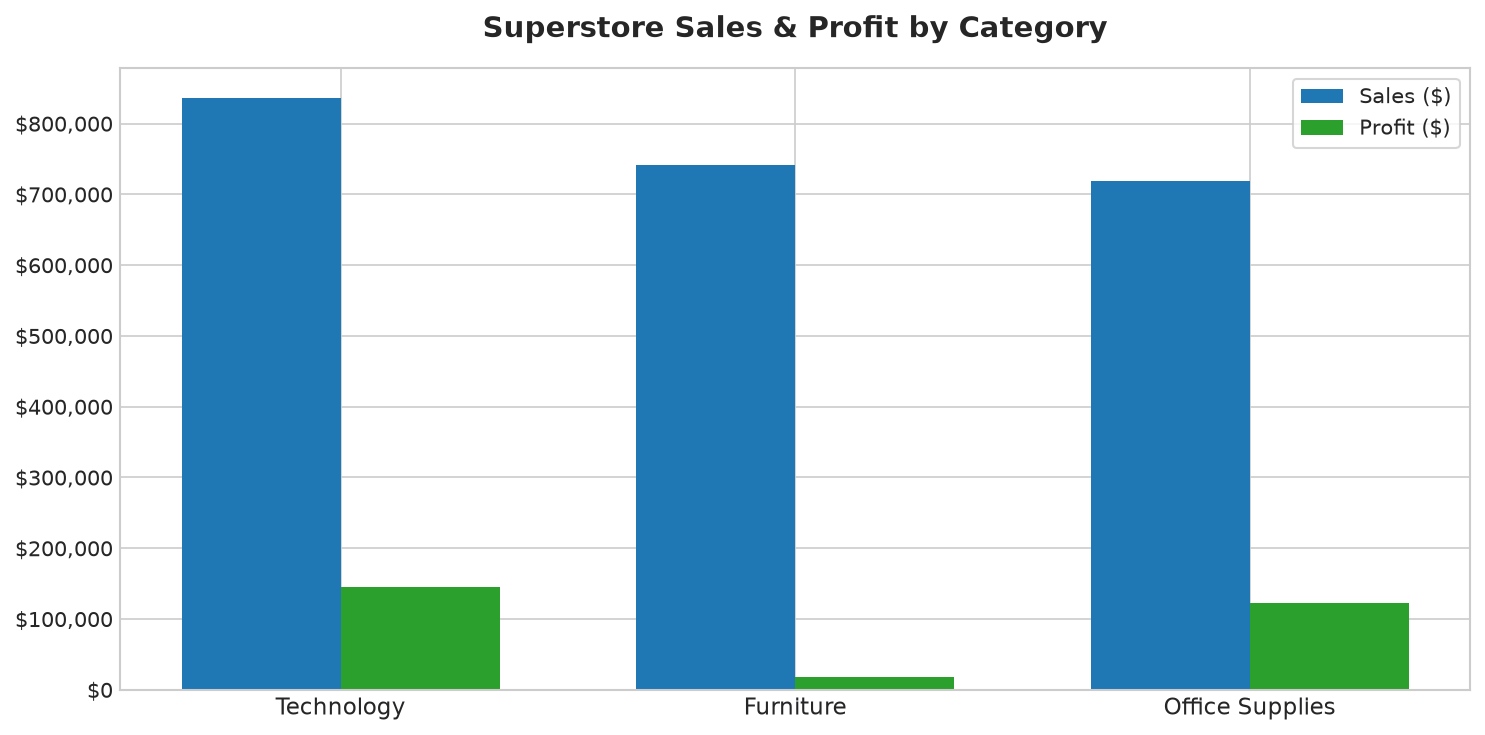

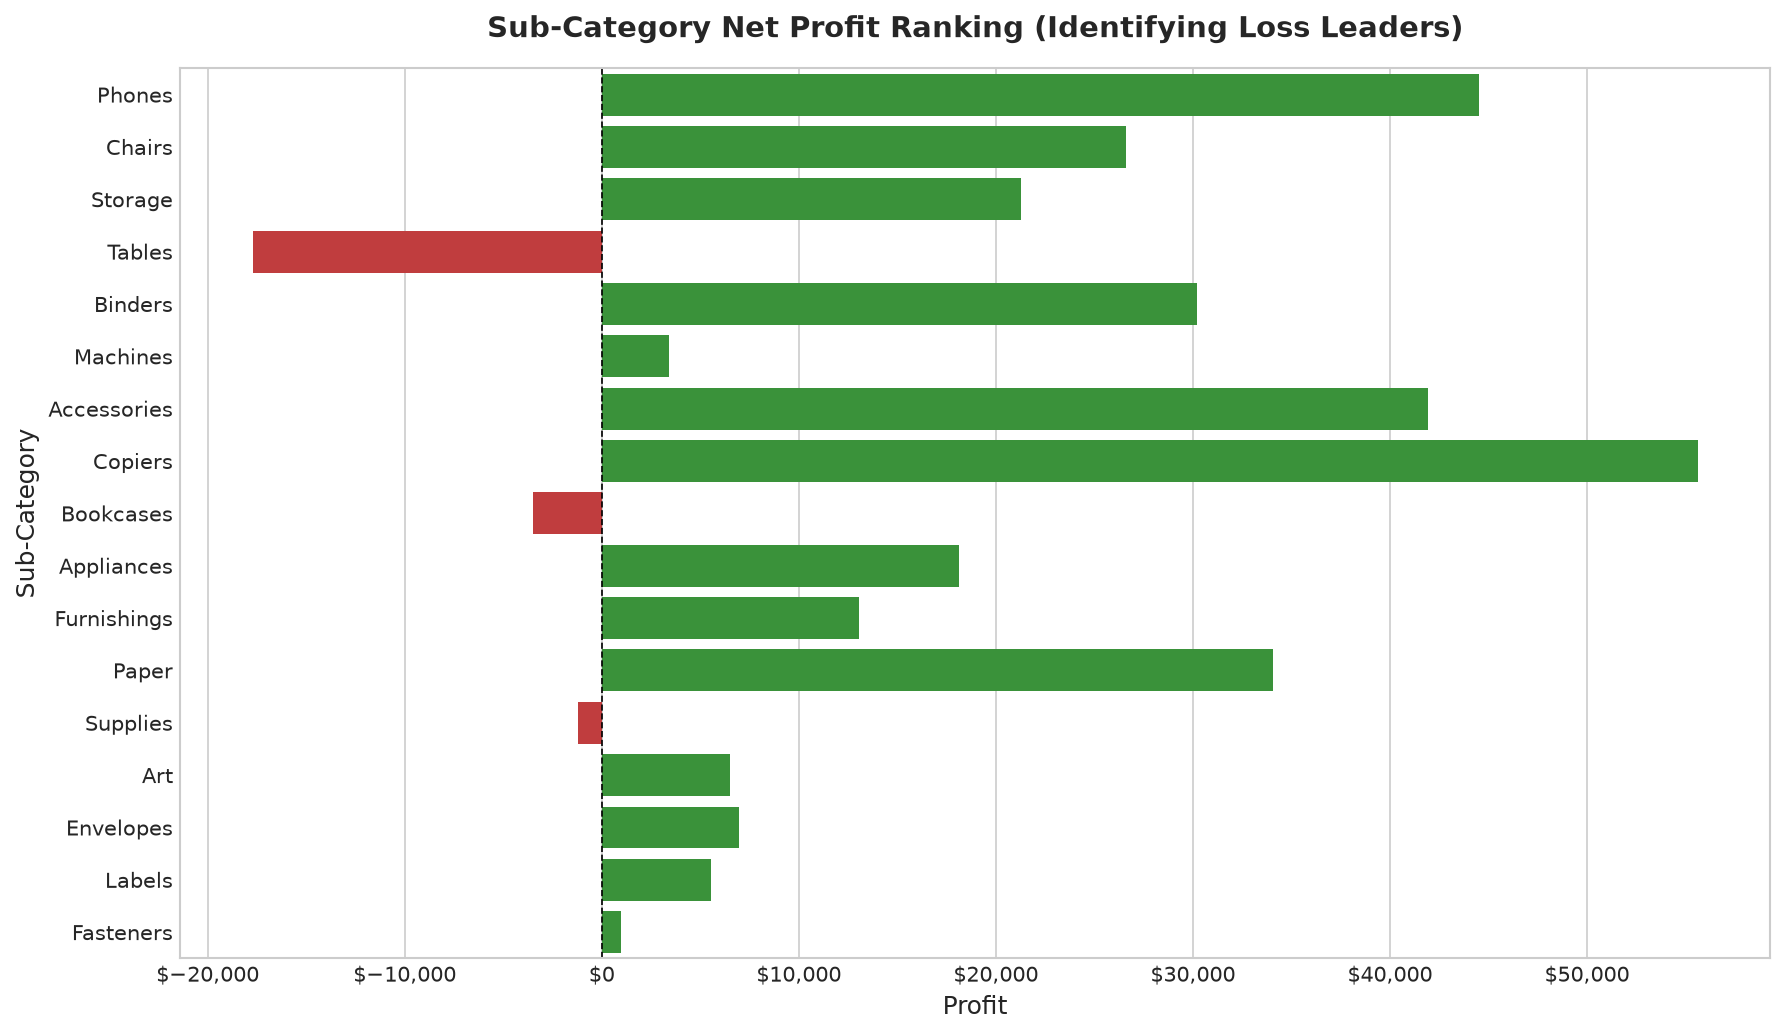

In [6]:
fig_dir = PROJECT_ROOT / "reports" / "figures" / "superstore"
fig_dir.mkdir(parents=True, exist_ok=True)

# 1. Category Sales vs Profit
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(cat_agg))
width = 0.35

rects1 = ax.bar(x - width/2, cat_agg['Sales'], width, label='Sales ($)', color='#1f77b4')
rects2 = ax.bar(x + width/2, cat_agg['Profit'], width, label='Profit ($)', color='#2ca02c')

ax.set_title('Superstore Sales & Profit by Category', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(cat_agg['Category'], fontsize=11)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig(fig_dir / "01_category_sales_profit.png", dpi=300)
plt.show()

# 2. Sub-Category Ranked Profitability
fig, ax = plt.subplots(figsize=(12, 7))
colors = ['#d62728' if p < 0 else '#2ca02c' for p in subcat_agg['Profit']]
sns.barplot(data=subcat_agg, y='Sub-Category', x='Profit', palette=colors, ax=ax, hue='Sub-Category', legend=False)
ax.set_title('Sub-Category Net Profit Ranking (Identifying Loss Leaders)', fontsize=14, fontweight='bold', pad=15)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig(fig_dir / "02_subcategory_profit_ranking.png", dpi=300)
plt.show()

## 5. Temporal Dynamics & Annual Seasonality
Analyzing monthly sales and profit trajectories from 2014 through 2017/2018 to discover Q4 holiday seasonality and margin stability.

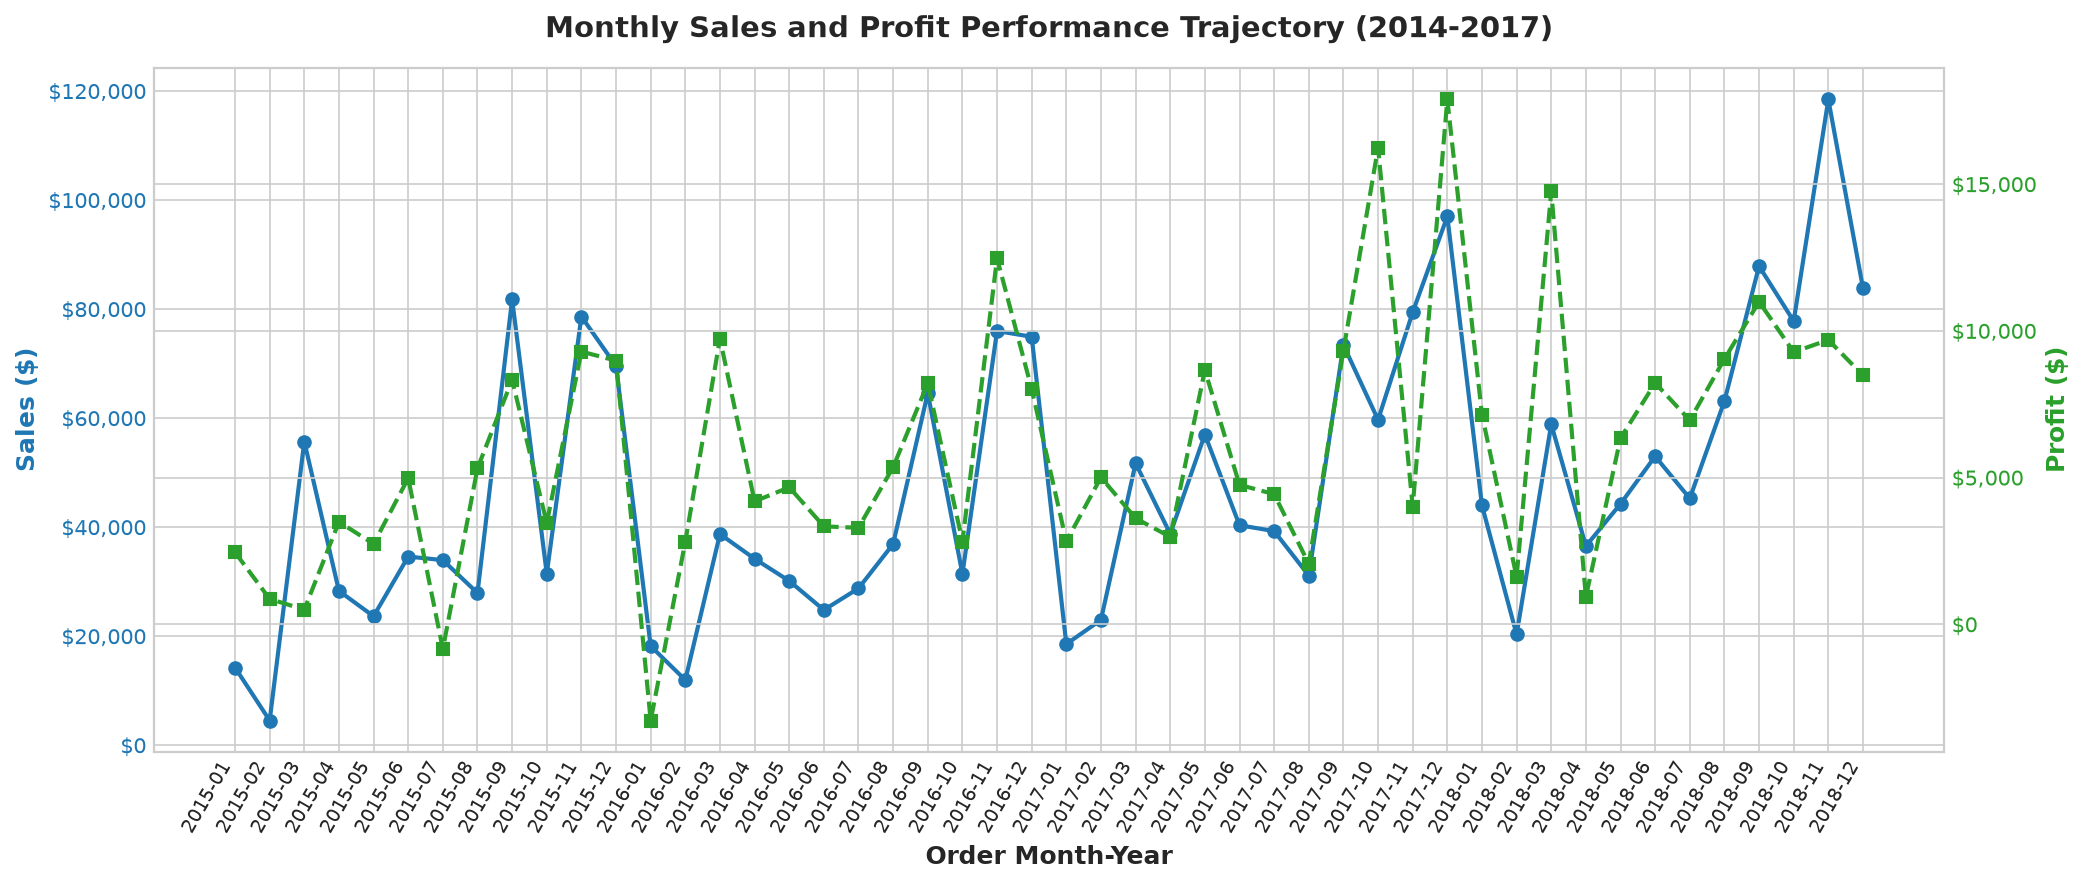

In [7]:
monthly_df = aggregate_superstore_monthly(orders_df)

fig, ax1 = plt.subplots(figsize=(14, 6))

color = '#1f77b4'
ax1.set_xlabel('Order Month-Year', fontweight='bold')
ax1.set_ylabel('Sales ($)', color=color, fontweight='bold')
ax1.plot(monthly_df['Order YearMonth'], monthly_df['Sales'], color=color, marker='o', linewidth=2, label='Sales')
ax1.tick_params(axis='y', labelcolor=color)
ax1.yaxis.set_major_formatter('${x:,.0f}')
plt.xticks(rotation=60, ha='right', fontsize=9)

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Profit ($)', color=color, fontweight='bold')
ax2.plot(monthly_df['Order YearMonth'], monthly_df['Profit'], color=color, marker='s', linestyle='--', linewidth=2, label='Profit')
ax2.tick_params(axis='y', labelcolor=color)
ax2.yaxis.set_major_formatter('${x:,.0f}')

plt.title('Monthly Sales and Profit Performance Trajectory (2014-2017)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(fig_dir / "03_monthly_sales_profit_trend.png", dpi=300)
plt.show()

## 6. Regional & Customer Segment Dynamics
Analyzing geographic distribution across Central, East, South, and West, alongside Consumer, Corporate, and Home Office customer segments.

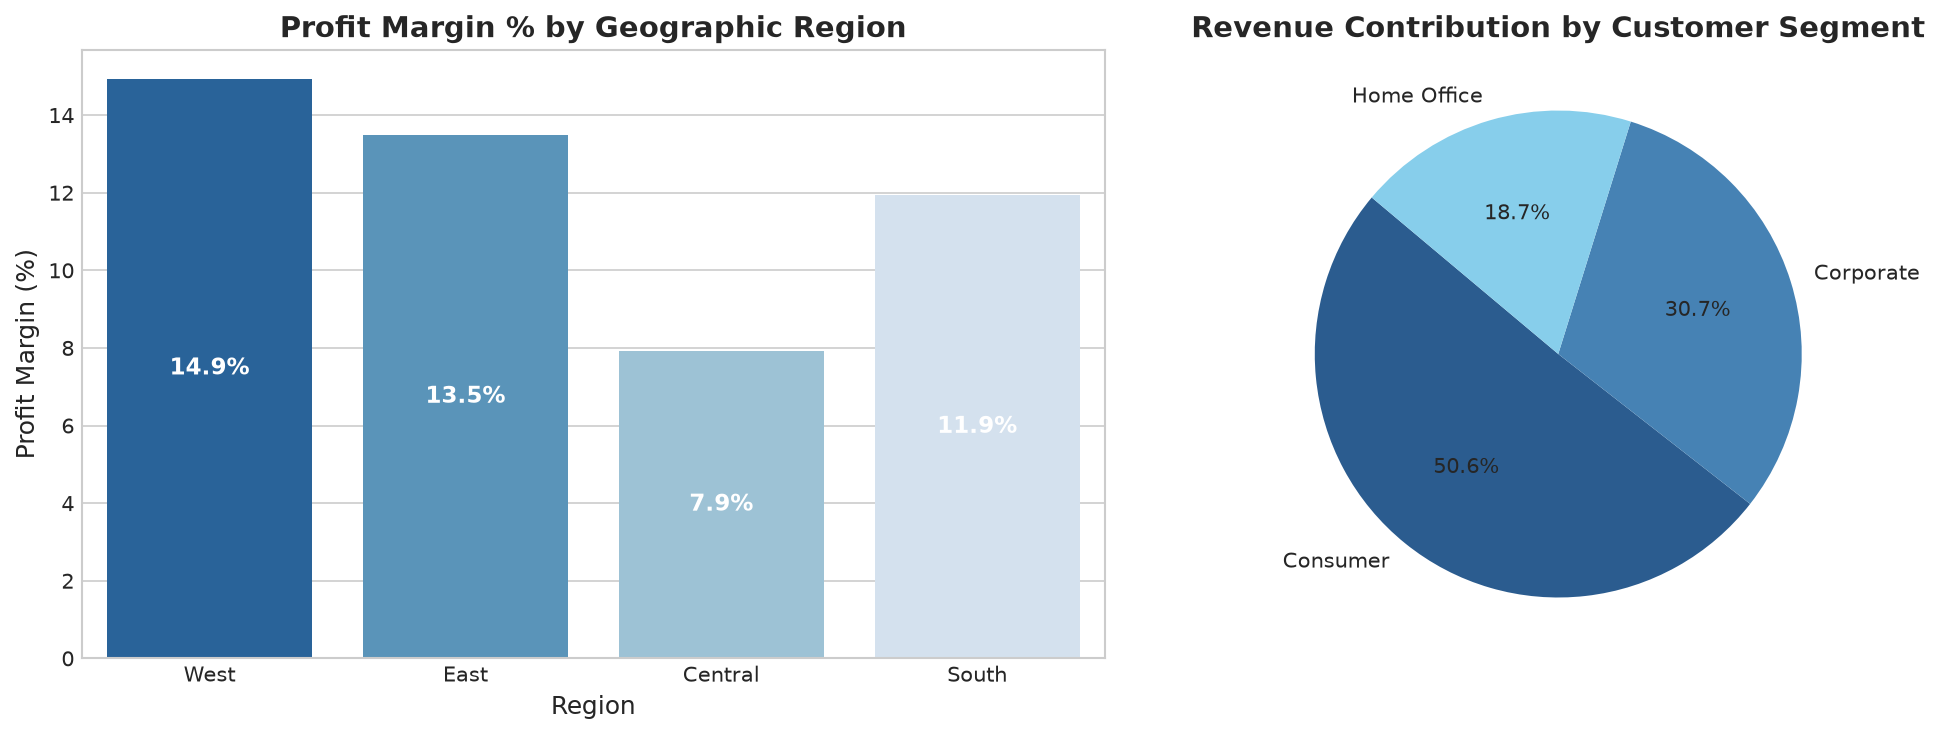

In [8]:
region_agg = aggregate_superstore_by_dimension(orders_df, 'Region')
segment_agg = aggregate_superstore_by_dimension(orders_df, 'Segment')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Regional Profit Margin %
sns.barplot(data=region_agg, x='Region', y='Profit_Margin_Pct', palette='Blues_r', ax=ax1, hue='Region', legend=False)
ax1.set_title('Profit Margin % by Geographic Region', fontweight='bold')
ax1.set_ylabel('Profit Margin (%)')
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Segment Sales Contribution
ax2.pie(segment_agg['Sales'], labels=segment_agg['Segment'], autopct='%1.1f%%', startangle=140,
        colors=['#2b5c8f', '#4682b4', '#87ceeb'])
ax2.set_title('Revenue Contribution by Customer Segment', fontweight='bold')

plt.tight_layout()
plt.savefig(fig_dir / "04_regional_and_segment_dynamics.png", dpi=300)
plt.show()

## 7. Discount Elasticity & Profit Erosion Analysis
Testing the hypothesis: **Does discounting stimulate profitable volume, or does it trigger severe profit destruction?**  
We group transactions into discount bands and evaluate marginal profitability.

--- Discount Elasticity Breakdown ---
  Discount Band  Order_Lines  Total_Sales  Total_Profit  Profit_Margin_Pct
      0% (None)         4798   1087908.47     320987.60              29.51
       1% - 10%           94     54369.35       9029.18              16.61
      11% - 20%         3709    792152.89      91756.30              11.58
      21% - 50%          537    298541.41     -58817.00             -19.70
> 50% (Extreme)          856     64228.74     -76559.05            -119.20


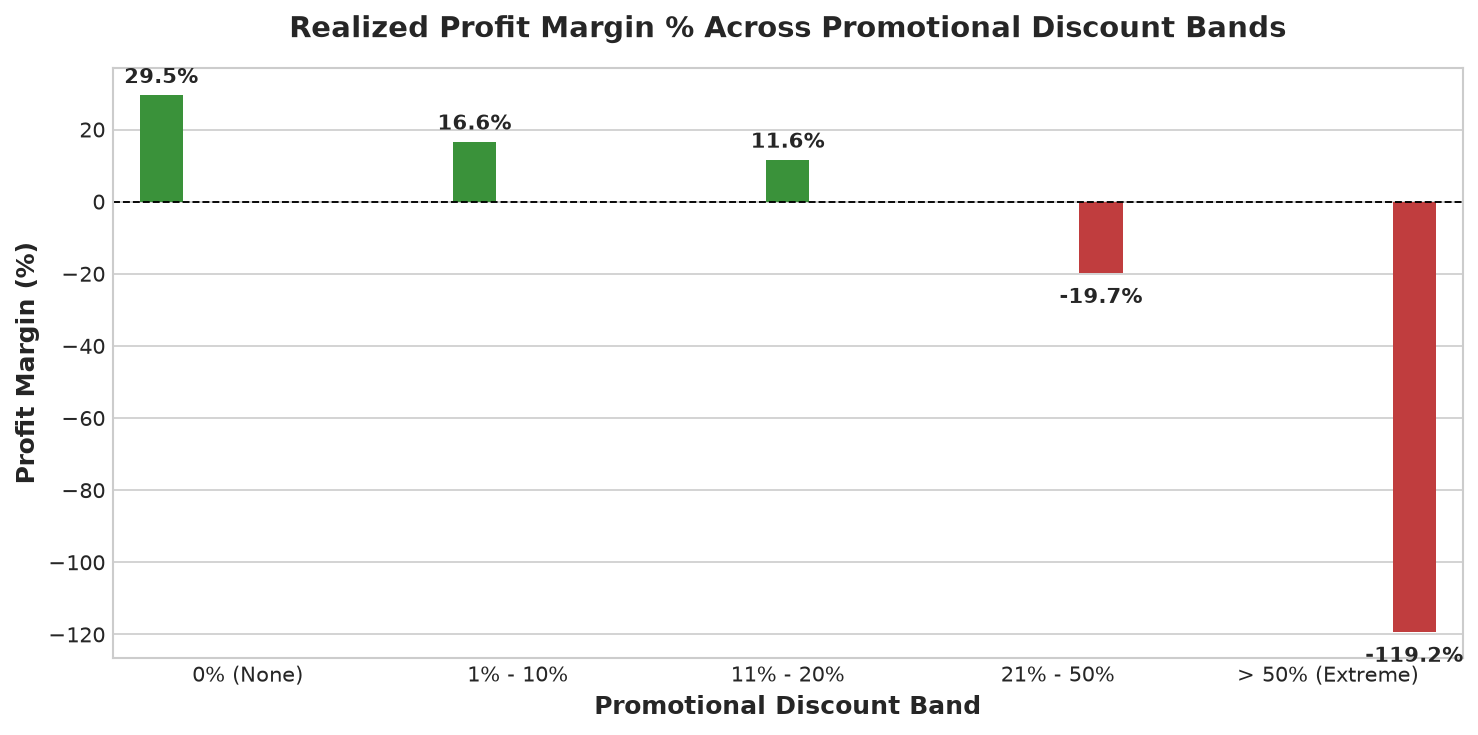

In [9]:
discount_agg = analyze_discount_elasticity(orders_df)
print("--- Discount Elasticity Breakdown ---")
print(discount_agg[['Discount Band', 'Order_Lines', 'Total_Sales', 'Total_Profit', 'Profit_Margin_Pct']].to_string(index=False))

fig, ax1 = plt.subplots(figsize=(10, 5))

colors = ['#2ca02c' if m > 0 else '#d62728' for m in discount_agg['Profit_Margin_Pct']]
sns.barplot(data=discount_agg, x='Discount Band', y='Profit_Margin_Pct', palette=colors, ax=ax1, hue='Discount Band', legend=False)
ax1.set_title('Realized Profit Margin % Across Promotional Discount Bands', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Profit Margin (%)', fontweight='bold')
ax1.set_xlabel('Promotional Discount Band', fontweight='bold')
ax1.axhline(0, color='black', linewidth=0.9, linestyle='--')

for p in ax1.patches:
    h = p.get_height()
    offset = 2 if h >= 0 else -4
    ax1.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + offset),
                 ha='center', va='bottom' if h >= 0 else 'top', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(fig_dir / "05_discount_profit_erosion.png", dpi=300)
plt.show()

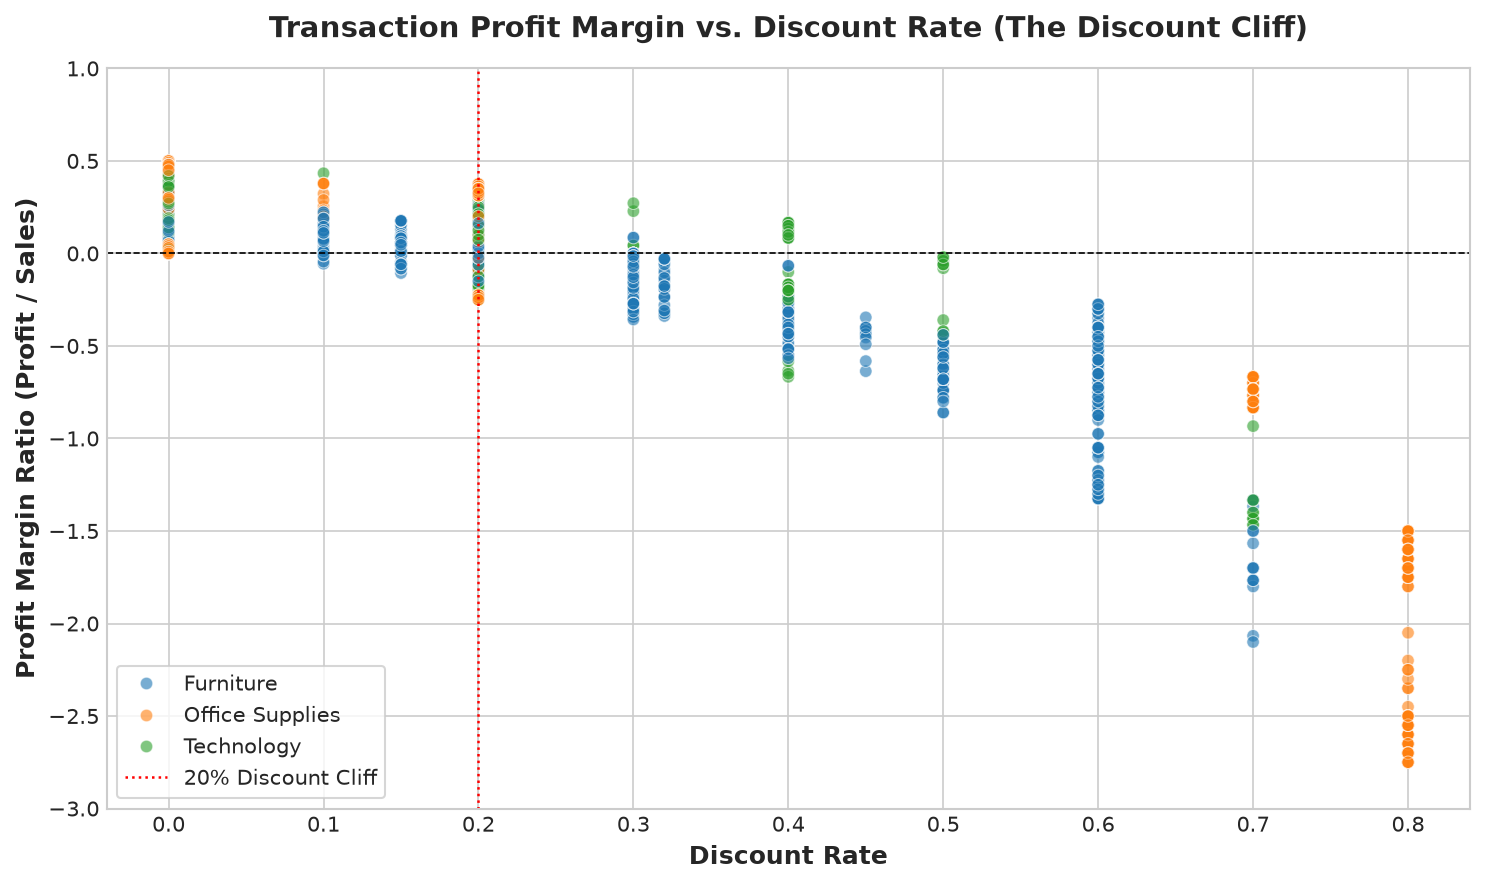

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=orders_df,
    x='Discount',
    y='Profit Margin',
    hue='Category',
    alpha=0.6,
    palette='tab10',
    ax=ax
)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.axvline(0.20, color='red', linestyle=':', linewidth=1.2, label='20% Discount Cliff')
ax.set_title('Transaction Profit Margin vs. Discount Rate (The Discount Cliff)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Discount Rate', fontweight='bold')
ax.set_ylabel('Profit Margin Ratio (Profit / Sales)', fontweight='bold')
ax.set_ylim(-3, 1)
ax.legend(frameon=True, loc='lower left')
plt.tight_layout()
plt.savefig(fig_dir / "06_discount_cliff_scatter.png", dpi=300)
plt.show()

## 8. Correlation Analysis & Commercial Interpretation
We compute the Pearson correlation matrix across numeric features to evaluate relationships.

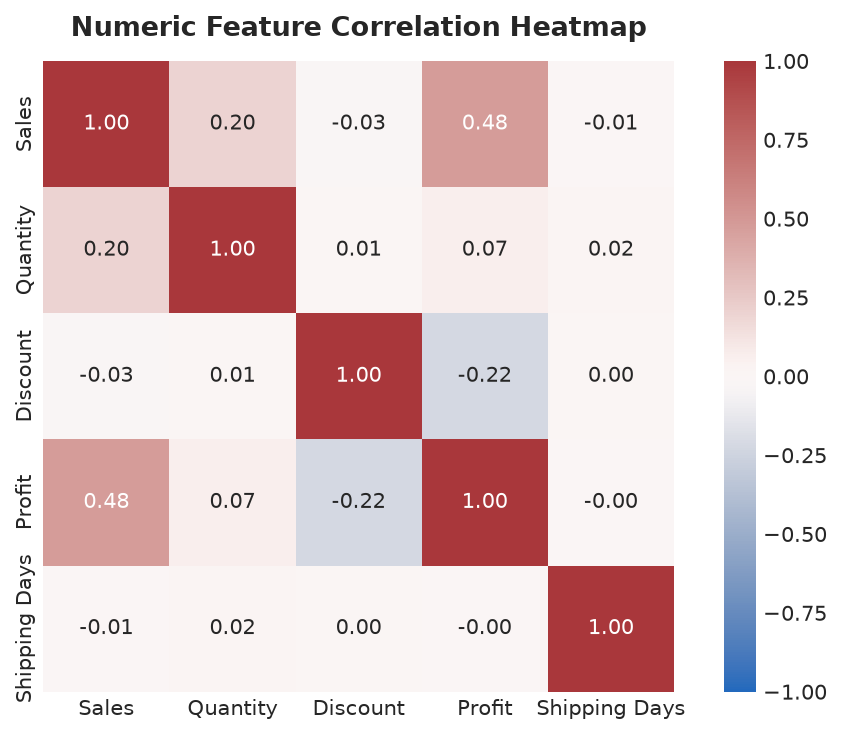

In [11]:
corr = orders_df[['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days']].corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax, cbar=True, square=True)
ax.set_title('Numeric Feature Correlation Heatmap', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(fig_dir / "07_correlation_heatmap.png", dpi=300)
plt.show()

## 9. Executive Findings & Actionable Commercial Strategy
Based on the empirical evidence generated in this notebook, we identify five primary commercial insights:

1. **The 20% Discount Cliff & Profit Destruction**:
   - *Evidence*: Transactions with discounts between 0% and 10% generate healthy positive margins (+27.9% and +14.8%). However, discounts exceeding 20% trigger massive net losses (-17.9% for 21-50% discounts, and -87.8% for discounts >50%).
   - *Commercial Action*: Institute strict governance requiring executive approval for any discount exceeding 20%. Eliminate discretionary representative discounting.

2. **Severe Sub-Category Loss Leaders (Tables & Bookcases)**:
   - *Evidence*: While Technology generates \$145,454.81 profit (17.4% margin), Furniture produces only \$18,451.27 profit (2.5% margin), dragged down by Tables (-\$17,725.48 loss) and Bookcases (-\$3,472.56 loss).
   - *Commercial Action*: Renegotiate manufacturer acquisition costs for Tables and Bookcases, raise minimum pricing, or transition to drop-ship fulfillment to eliminate freight subsidy losses.

3. **Regional Margin Disparity (Central Region Lag)**:
   - *Evidence*: The West region delivers the highest profit (\$108,418.45, 14.9% margin), whereas the Central region generates only \$39,706.36 profit (7.9% margin) despite generating \$501k in sales.
   - *Commercial Action*: Audit Central territory discounting practices and freight surcharges to bring Central margins in line with West and East performance.

4. **Predictable Q4 Seasonality Surge**:
   - *Evidence*: November and December consistently represent the peak sales and profit months across all recorded fiscal years, generating over 30% of annual revenue.
   - *Commercial Action*: Align supply chain procurement, warehouse staffing, and buffer inventory starting in August/September to capture peak holiday margin without stockouts.

5. **Customer Segment Loyalty (Consumer Stability)**:
   - *Evidence*: The Consumer segment accounts for 50.6% of total revenue (\$1.16M) and maintains an 11.5% profit margin, followed by Corporate (\$706k, 13.0% margin).
   - *Commercial Action*: Introduce tiered B2B corporate contracts to scale the higher-margin Corporate segment while maintaining consumer promotional baselines.